In [1]:
import os, sys
import torch


_SRC_DIR = '../src/'
if _SRC_DIR not in sys.path:
    sys.path.append(_SRC_DIR)

import pde_models_sde
import viz


In [2]:
def build_pde_model(d: int) -> pde_models_sde.SmoluchowskiVariational:
    """Construct the double-well model and its first-step variational form."""
    well_depths = torch.tensor(
        [0.8067, 1.0391, 1.0101, 0.7722, 1.0593, 1.0706, 0.9805, 0.9893, 0.9514, 1.1419]
    )
    if d > len(well_depths):
        raise ValueError(f"d={d} exceeds the {len(well_depths)} configured well depths.")

    base_model = pde_models_sde.SmoluchowskiDoubleWell(
        d=d,
        a=well_depths[:d],
        beta=1.0,
        Z=1.0,
    )
    return pde_models_sde.SmoluchowskiVariational(
        base_model,
        d=d,
        alpha=1.0,
        beta=1.0,
        dt=0.01,
    )
d=2
pde_model = build_pde_model(d)

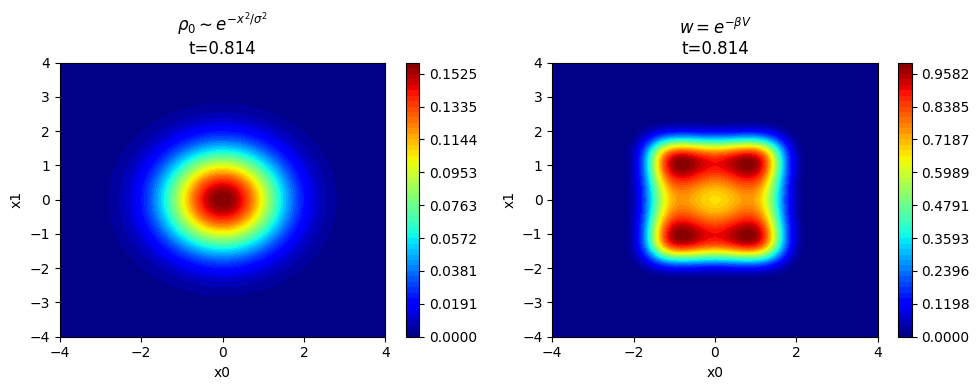

In [3]:

tr0 = lambda X: pde_model.tilde_rho_0(X[:, :-1])
r0 = lambda X: pde_model.rho_0(X[:, :-1])
w = lambda X: pde_model.w(X[:, :-1])

lim = 4.0
options = {
        "d": d,
        "plot_dims": [0, 1],
        "fixed_dims_vals": 0.5 * torch.ones(d),
        "x_start": -lim,
        "x_end": lim
}

plotter = viz.FunctionPlotter(**options)
#plotter.add_panel('tilde_rho_0', title="tr0").heatmap(tr0)
plotter.add_panel('rho_0', title=r"$\rho_0 \sim e^{-x^2/\sigma^2}$").heatmap(r0)
plotter.add_panel('w', title=r"$w=e^{-\beta V}$").heatmap(w)
#plotter.save_plot('test.png')
plotter.show_plot()

$$
\rho = \tilde\rho\cdot w
$$
$$
\tilde\rho = \rho / w = \rho\,e^{\beta V}
$$
$$
\tilde\rho_0 = \rho_0 / w = e^{- \sum x_i^2 / \sigma^2} e^{\beta V}
$$


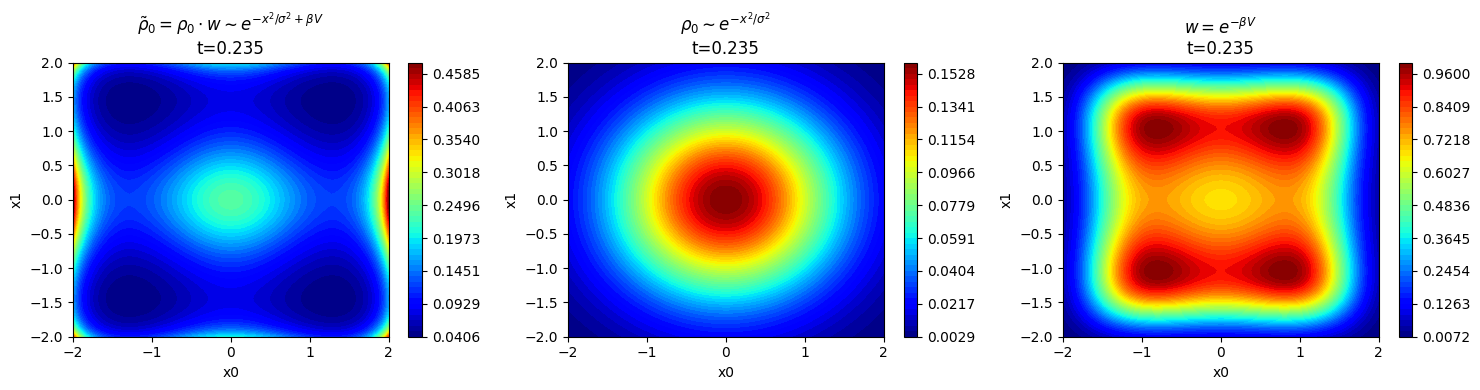

In [4]:
mp = torch.log
mp = lambda x: x

tr0 = lambda X: mp(pde_model.tilde_rho_0(X[:, :-1]))
r0 = lambda X: mp(pde_model.rho_0(X[:, :-1]))
w = lambda X: mp(pde_model.w(X[:, :-1]))

lim = 2.0
options = {
        "d": d,
        "plot_dims": [0, 1],
        "fixed_dims_vals": 0.5 * torch.ones(d),
        "x_start": -lim,
        "x_end": lim
}

plotter = viz.FunctionPlotter(**options)
plotter.add_panel('tilde_rho_0', title=r"$\tilde\rho_0 = \rho_0\cdot w \sim e^{-x^2/\sigma^2 + \beta V}$").heatmap(tr0)
plotter.add_panel('rho_0', title=r"$\rho_0 \sim e^{-x^2/\sigma^2}$").heatmap(r0)
plotter.add_panel('w', title=r"$w=e^{-\beta V}$").heatmap(w)
plotter.show_plot()

In [66]:
n_samples = 1000
device = 'cpu'
dtype = torch.float32

dataset_raw_n = torch.randn(n_samples//2, d, device=device, dtype=dtype)
indx = torch.sqrt(torch.sum(dataset_raw_n**2, dim=1)) < 2.0

dataset_raw_n[indx, :].shape, torch.sum(indx) / (n_samples//2)

(torch.Size([428, 2]), tensor(0.8560))

In [67]:
dataset_raw = torch.concatenate( (dataset_raw_n, dataset_raw_n), dim=0 )
dataset_raw.shape

torch.Size([1000, 2])